In [2]:
import pandas as pd
import numpy as np

df4=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv',low_memory=False)

In [11]:
df4.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [4]:
df4.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [5]:
df4.head(10)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
5,6,5,2015-07-31,5651,589,1,1,0,1
6,7,5,2015-07-31,15344,1414,1,1,0,1
7,8,5,2015-07-31,8492,833,1,1,0,1
8,9,5,2015-07-31,8565,687,1,1,0,1
9,10,5,2015-07-31,7185,681,1,1,0,1


In [7]:
from sklearn.cluster import KMeans

In [10]:
df4['Date'] = pd.to_datetime(df4['Date'], format='%Y-%m-%d', errors='coerce')

In [12]:
kmeans = KMeans(n_clusters=2, random_state=42)

# 3. Fit the model and predict cluster labels
labels = kmeans.fit_predict(df4.select_dtypes(include=[np.number]).fillna(0))  # Fill NaN values with 0 for clustering

# 4. Inspect results
print("Cluster labels:", labels)
print("Cluster centroids:\n", kmeans.cluster_centers_)

Cluster labels: [1 0 0 ... 1 1 1]
Cluster centroids:
 [[5.58189716e+02 3.32579807e+00 8.82543590e+03 9.47372551e+02
  1.00000000e+00 6.02947388e-01 2.02840445e-01]
 [5.58644711e+02 4.60075478e+00 3.04040439e+03 3.51684806e+02
  6.77928734e-01 1.83171195e-01 1.56975661e-01]]


In [13]:
import matplotlib.pyplot as plt

In [19]:
print(labels)


[1 0 0 ... 1 1 1]


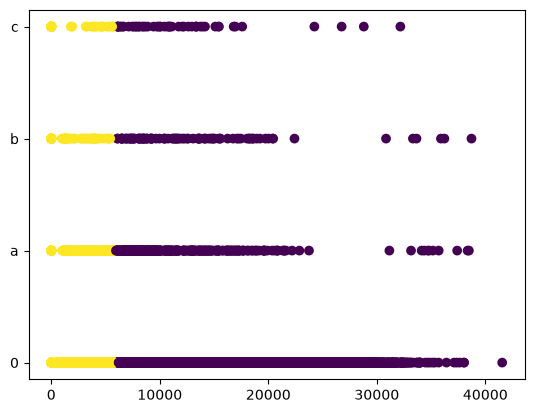

In [16]:
plt.scatter(df4['Sales'],df4['StateHoliday'],c=labels)

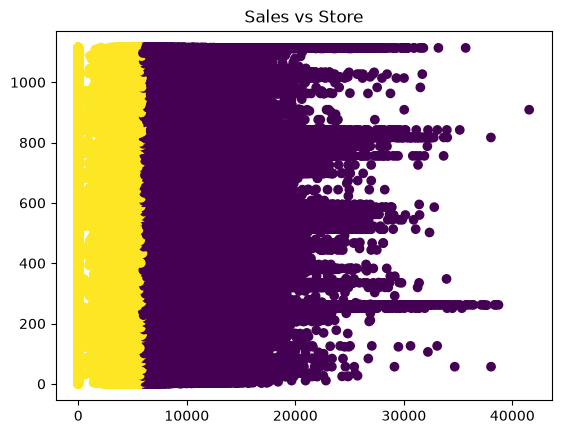

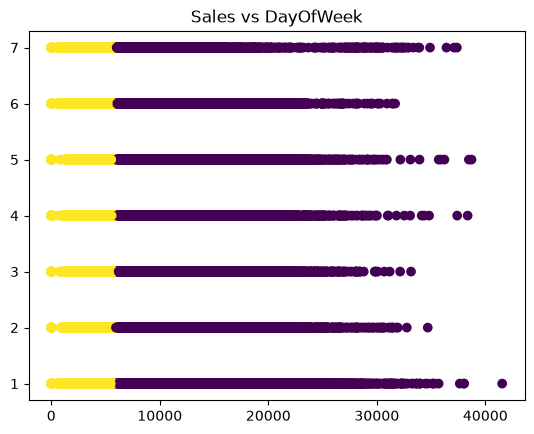

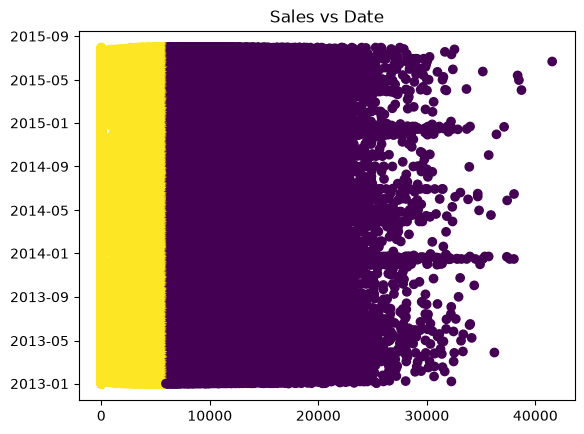

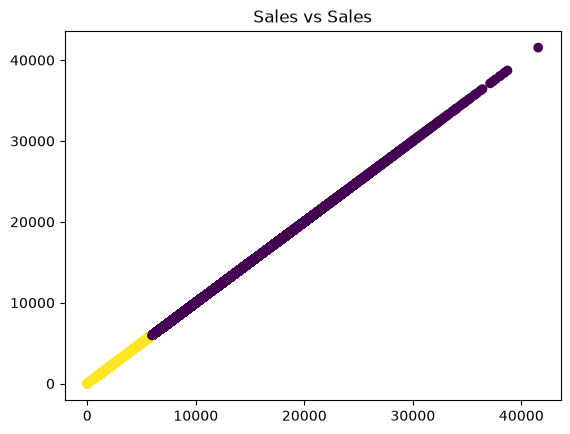

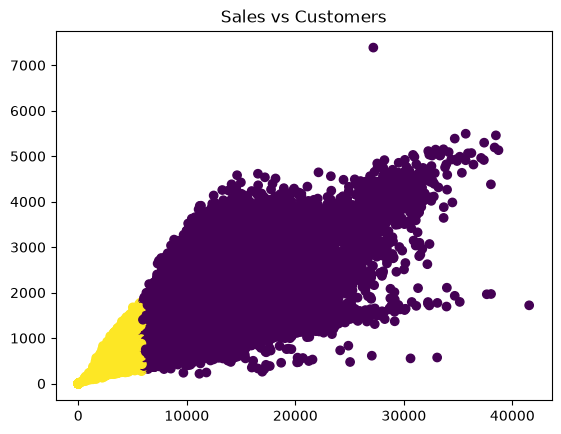

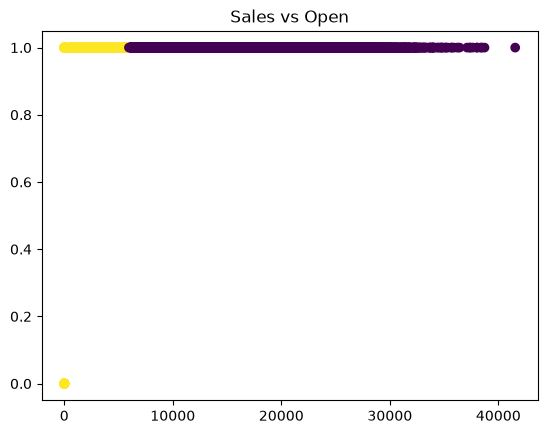

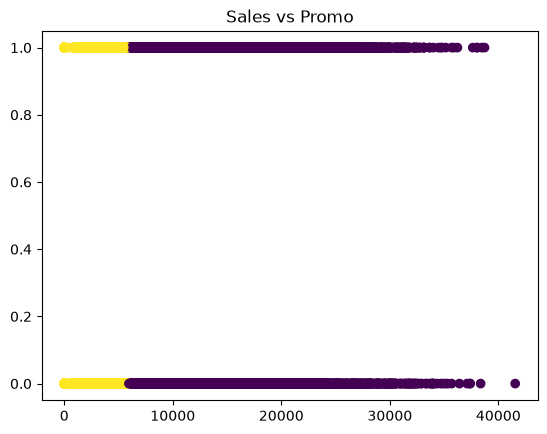

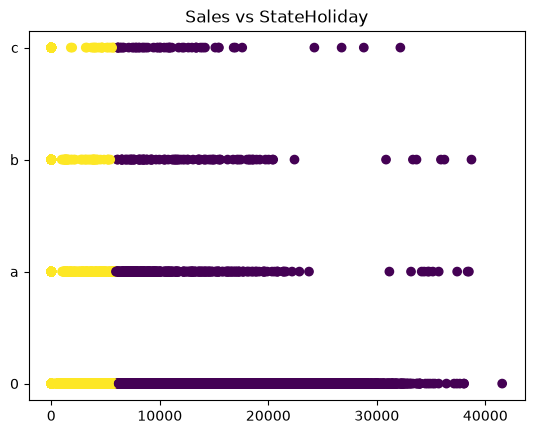

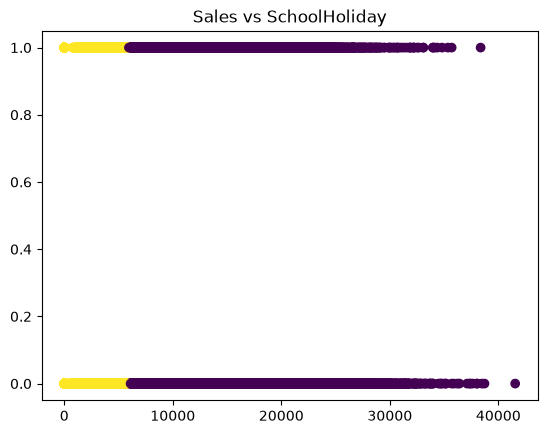

In [18]:
for i in df4.columns:
    plt.figure()  # <-- यह लाइन हर कॉलम के लिए नया ग्राफ बनाएगी
    plt.scatter(df4['Sales'], df4[i], c=labels)
    plt.title(f'Sales vs {i}')
    plt.show()



In [22]:
df4.groupby('Open')['Sales'].sum()

Open
0             0
1    5873180623
Name: Sales, dtype: int64

In [ ]:
df4.groupby('SchoolHoliday')['Sales'].sum()

SchoolHoliday
0    4696260531
1    1176920092
Name: Sales, dtype: int64

In [27]:
4696260531/516035131

9.100660495535138

In [28]:
1176920092/128006624


9.194212418257354

In [30]:
df4.groupby('StateHoliday')['Customers'].sum()

StateHoliday
0    642797995
a       887746
b       244599
c       111415
Name: Customers, dtype: int64

In [32]:
df4.groupby('StateHoliday')['SchoolHoliday'].value_counts()

StateHoliday  SchoolHoliday
0             0                819949
              1                166210
a             0                 15055
              1                  5205
b             1                  6206
              0                   484
c             1                  4100
Name: count, dtype: int64

In [33]:
819949/166210

4.933210998134889

In [34]:
15055/5205

2.8924111431316044

In [26]:
df4.groupby('SchoolHoliday')['Customers'].sum()

SchoolHoliday
0    516035131
1    128006624
Name: Customers, dtype: int64

In [35]:
df4[df4['StateHoliday'] == 'c']['Sales'].sum()

np.int64(691806)

In [40]:
len(df4[df4['StateHoliday'] == 'c'])

4100

In [44]:
df4[df4['StateHoliday'] == 'c']['Customers'].sum()


np.int64(111415)

In [45]:
691806/111415

6.209271642058969

In [46]:
df4['StateHoliday'].unique()

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [47]:
for i in df4['StateHoliday'].unique():
    print(f"{i}: {df4[df4['StateHoliday'] == i]['Sales'].sum() / df4[df4['StateHoliday'] == i]['Customers'].sum()}")

0: 9.124429157561389
a: 6.63512423598642
b: 5.861610227351706
c: 6.209271642058969


In [48]:
df5=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\store.csv',low_memory=False)
pd.merge(df4,df5,on='Store',how='left').groupby('StoreType')['Sales'].sum()



StoreType
a    3165334859
b     159231395
c     783221426
d    1765392943
Name: Sales, dtype: int64

In [49]:
pd.merge(df4,df5,on='Store',how='left').groupby('StoreType')['Customers'].sum()

StoreType
a    363541434
b     31465621
c     92129705
d    156904995
Name: Customers, dtype: int64

In [50]:
merged_df = pd.merge(df4, df5, on='Store', how='left')

# Har StoreType ke liye Sales aur Customers ka sum nikalna
grouped = merged_df.groupby('StoreType')[['Sales', 'Customers']].sum()

# Sales ko Customers se divide karna
grouped['Sales_per_Customer'] = grouped['Sales'] / grouped['Customers']

print(grouped)


                Sales  Customers  Sales_per_Customer
StoreType                                           
a          3165334859  363541434            8.706944
b           159231395   31465621            5.060488
c           783221426   92129705            8.501291
d          1765392943  156904995           11.251350


In [51]:
merged_df = pd.merge(df4, df5, on='Store', how='left')

# Har StoreType ke liye Sales aur Customers ka sum nikalna
grouped = merged_df.groupby('Promo2')[['Sales', 'Customers']].sum()

# Sales ko Customers se divide karna
grouped['Sales_per_Customer'] = grouped['Sales'] / grouped['Customers']

print(grouped)


             Sales  Customers  Sales_per_Customer
Promo2                                           
0       3111542628  357125490            8.712743
1       2761637995  286916265            9.625240


In [52]:
merged_df = pd.merge(df4, df5, on='Store', how='left')

# Har StoreType ke liye Sales aur Customers ka sum nikalna
grouped = merged_df.groupby('PromoInterval')[['Sales', 'Customers']].sum()

# Sales ko Customers se divide karna
grouped['Sales_per_Customer'] = grouped['Sales'] / grouped['Customers']

print(grouped)


                       Sales  Customers  Sales_per_Customer
PromoInterval                                              
Feb,May,Aug,Nov    629869118   65162315            9.666156
Jan,Apr,Jul,Oct   1630451279  168814688            9.658231
Mar,Jun,Sept,Dec   501317598   52939262            9.469675


In [53]:
# Q1 (25th percentile) aur Q3 (75th percentile) nikalna
Q1 = merged_df['Sales'].quantile(0.25)
Q3 = merged_df['Sales'].quantile(0.75)
IQR = Q3 - Q1

# Lower aur Upper limit set karna
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Outliers filter karke dekhna
outliers = merged_df[(merged_df['Sales'] < lower_limit) | (merged_df['Sales'] > upper_limit)]
print(f"Total Outliers in Sales: {len(outliers)}")


Total Outliers in Sales: 26694


In [54]:
# Q1 (25th percentile) aur Q3 (75th percentile) nikalna
Q1 = merged_df['Customers'].quantile(0.25)
Q3 = merged_df['Customers'].quantile(0.75)
IQR = Q3 - Q1

# Lower aur Upper limit set karna
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Outliers filter karke dekhna
outliers = merged_df[(merged_df['Customers'] < lower_limit) | (merged_df['Customers'] > upper_limit)]
print(f"Total Outliers in Customers : {len(outliers)}")


Total Outliers in Customers : 38095


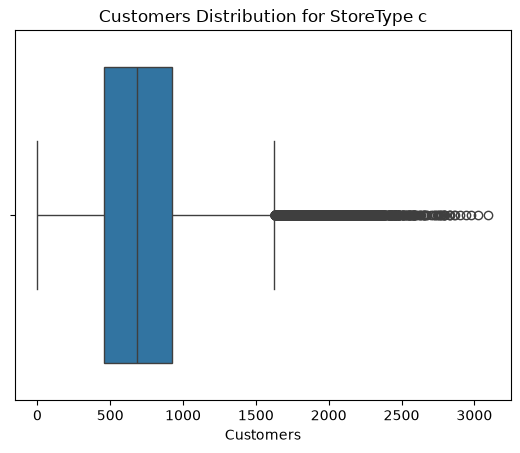

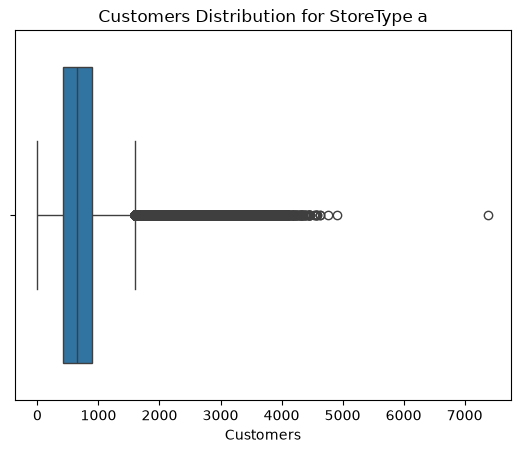

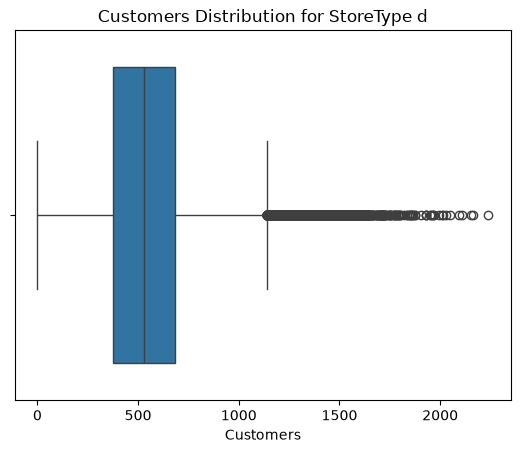

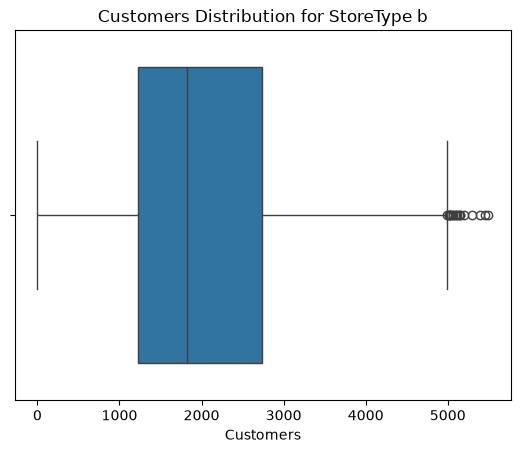

In [61]:

import seaborn as sns
import matplotlib.pyplot as plt
for i in merged_df['StoreType'].unique():
    plt.figure()  # <-- यह लाइन हर StoreType के लिए नया ग्राफ बनाएगी
    sns.boxplot(x=merged_df[merged_df['StoreType'] == i]['Customers'])
    plt.title(f'Customers Distribution for StoreType {i}')
    plt.show()



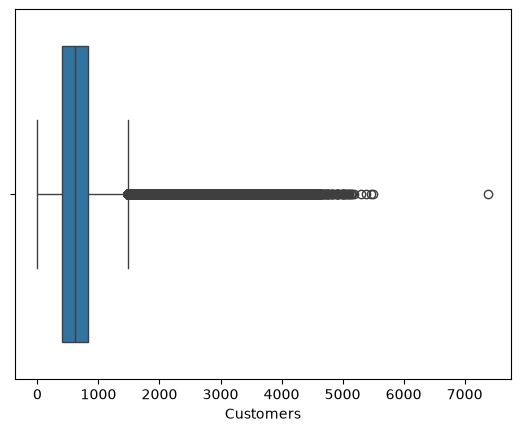

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=merged_df['Customers'])
plt.show()


<Axes: xlabel='Sales', ylabel='Count'>

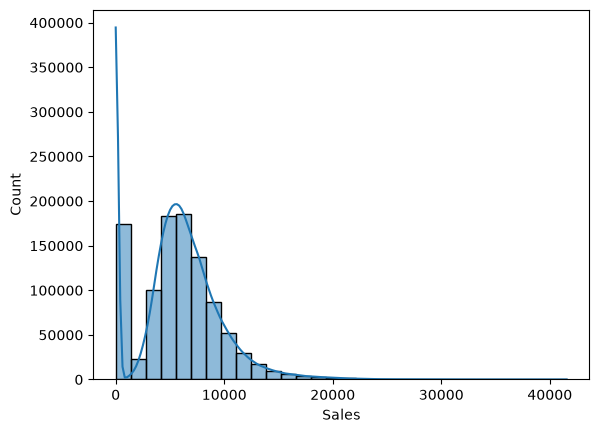

In [58]:
sns.histplot(x=merged_df['Sales'], bins=30, kde=True)

<Axes: xlabel='Customers', ylabel='Count'>

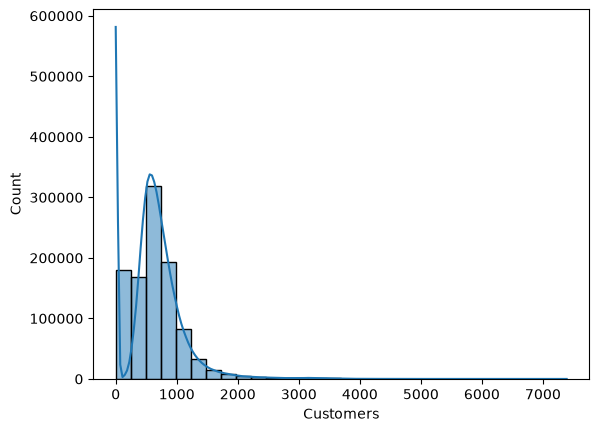

In [60]:
sns.histplot(x=merged_df['Customers'], bins=30, kde=True)

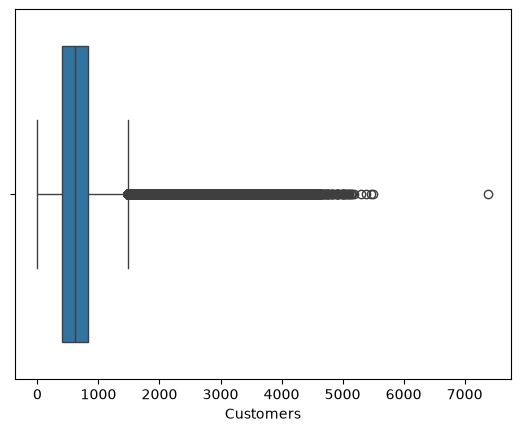

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=merged_df['Customers'])
plt.show()


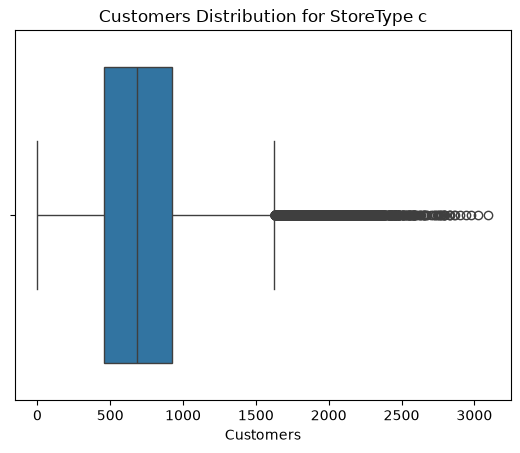

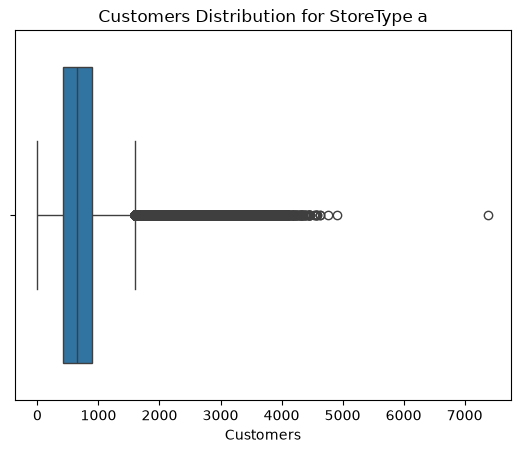

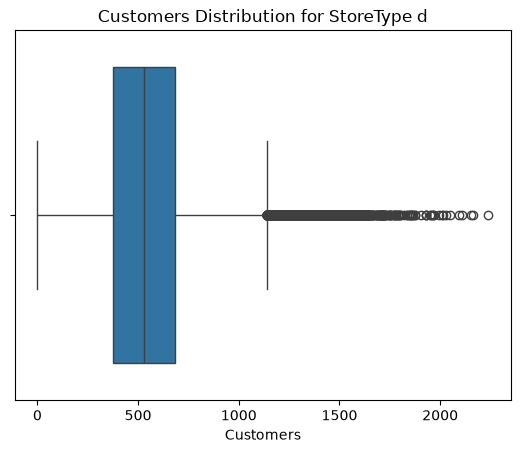

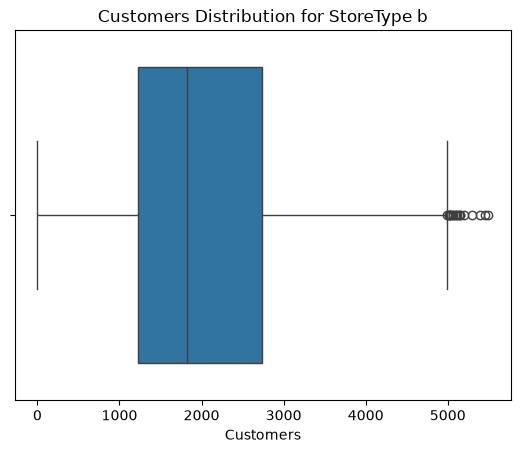

In [62]:
for i in merged_df['StoreType'].unique():
    plt.figure()  # <-- यह लाइन हर StoreType के लिए नया ग्राफ बनाएगी
    sns.boxplot(x=merged_df[merged_df['StoreType'] == i]['Customers'])
    plt.title(f'Customers Distribution for StoreType {i}')
    plt.show()

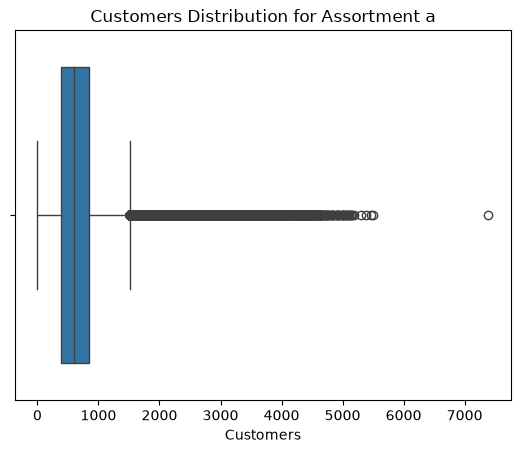

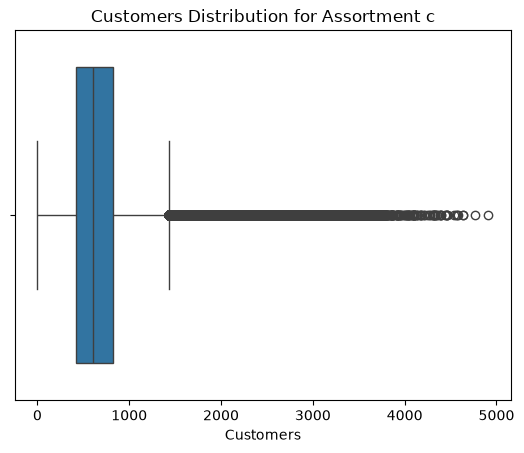

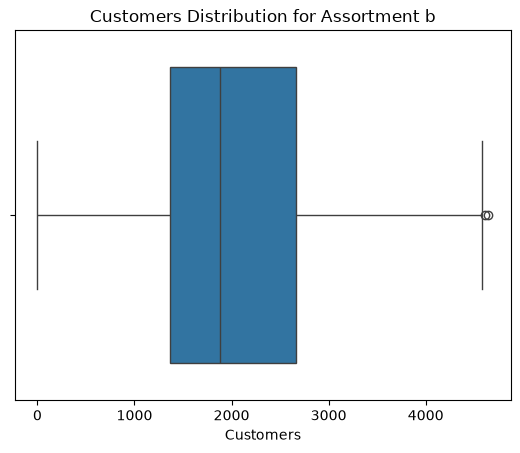

In [63]:
for i in merged_df['Assortment'].unique():
    plt.figure()  # <-- यह लाइन हर StoreType के लिए नया ग्राफ बनाएगी
    sns.boxplot(x=merged_df[merged_df['Assortment'] == i]['Customers'])
    plt.title(f'Customers Distribution for Assortment {i}')
    plt.show()


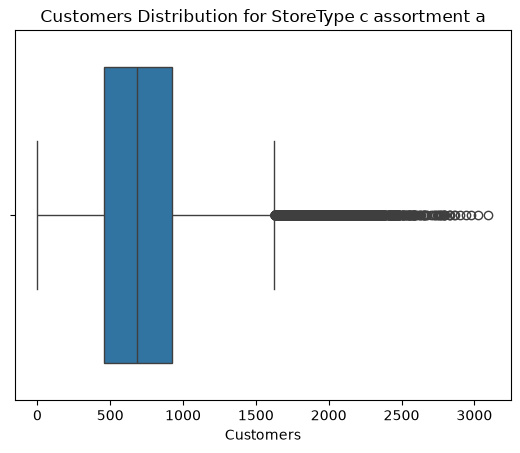

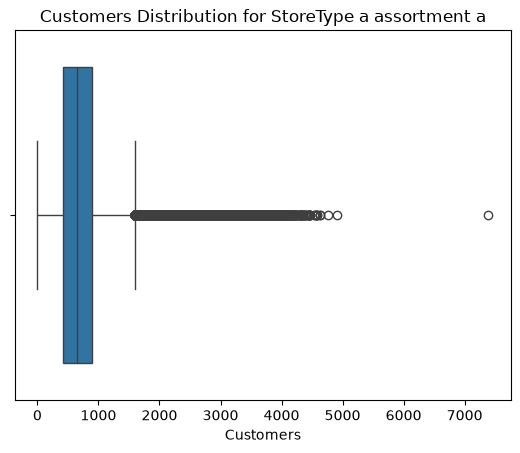

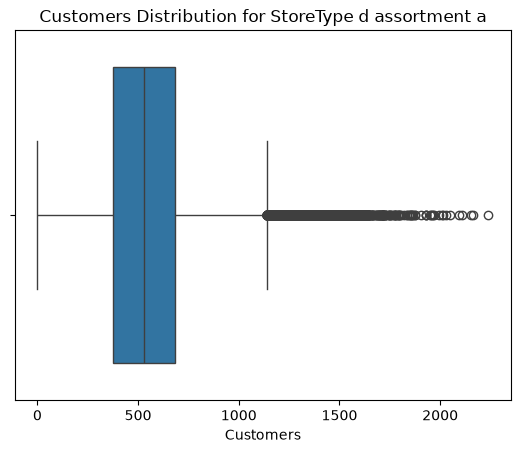

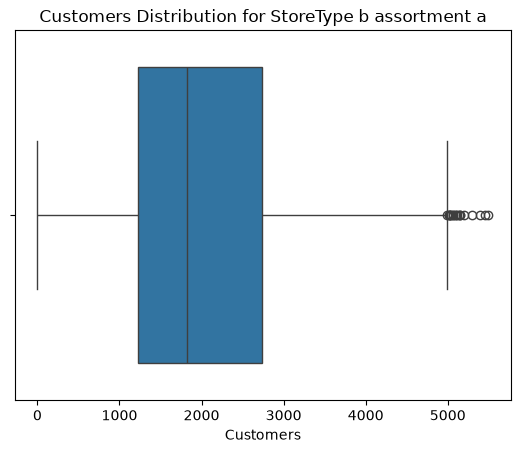

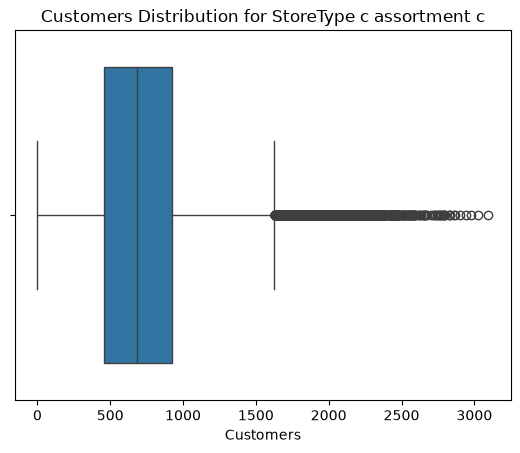

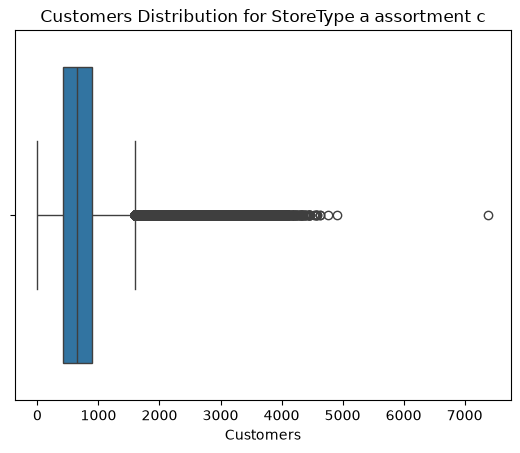

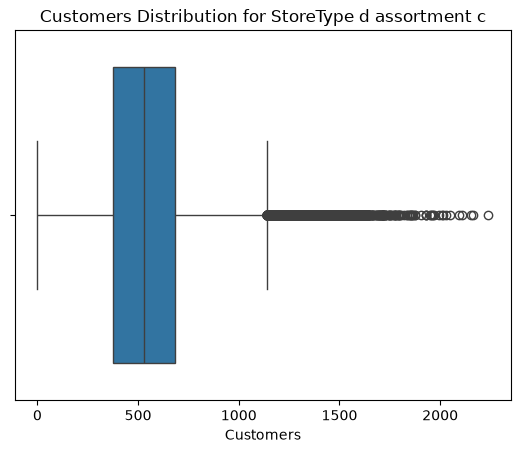

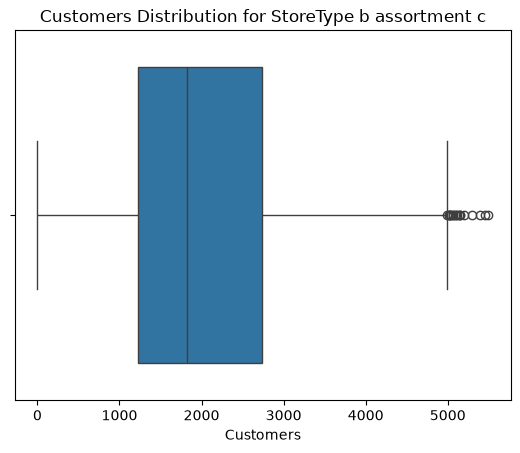

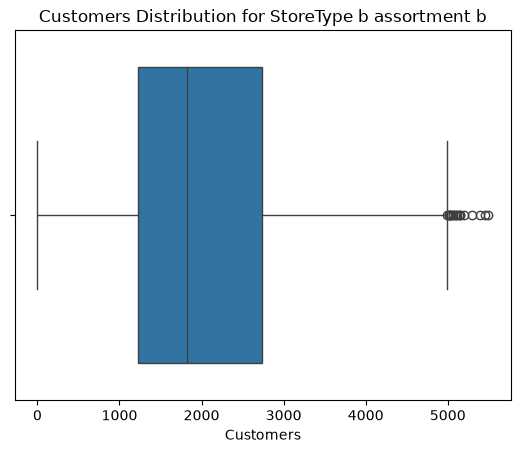

In [65]:
for j in merged_df['Assortment'].unique():
    for i in merged_df[merged_df['Assortment'] == j]['StoreType'].unique():
        plt.figure()  # <-- यह लाइन हर StoreType के लिए नया ग्राफ बनाएगी
        sns.boxplot(x=merged_df[merged_df['StoreType'] == i]['Customers'])
        plt.title(f'Customers Distribution for StoreType {i} assortment {j}')
    plt.show()

In [67]:
for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    print(merged_df[merged_df['StoreType'] == i]['Customers'].describe())

Description for StoreType c:
count    136840.000000
mean        673.265894
std         430.708776
min           0.000000
25%         455.000000
50%         682.000000
75%         924.000000
max        3096.000000
Name: Customers, dtype: float64
Description for StoreType a:
count    551627.00000
mean        659.03488
std         462.93032
min           0.00000
25%         414.00000
50%         647.00000
75%         890.00000
max        7388.00000
Name: Customers, dtype: float64
Description for StoreType d:
count    312912.000000
mean        501.434892
std         292.301770
min           0.000000
25%         375.000000
50%         530.000000
75%         681.000000
max        2239.000000
Name: Customers, dtype: float64
Description for StoreType b:
count    15830.000000
mean      1987.720846
std        940.088627
min          0.000000
25%       1228.000000
50%       1820.000000
75%       2732.000000
max       5494.000000
Name: Customers, dtype: float64


In [68]:
for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    print(merged_df[merged_df['StoreType'] == i]['Sales'].describe())

Description for StoreType c:
count    136840.000000
mean       5723.629246
std        3721.700886
min           0.000000
25%        3789.000000
50%        5766.000000
75%        7849.000000
max       31448.000000
Name: Sales, dtype: float64
Description for StoreType a:
count    551627.000000
mean       5738.179710
std        3964.028134
min           0.000000
25%        3508.000000
50%        5618.000000
75%        7860.000000
max       41551.000000
Name: Sales, dtype: float64
Description for StoreType d:
count    312912.000000
mean       5641.819243
std        3473.393781
min           0.000000
25%        3986.000000
50%        5826.000000
75%        7691.000000
max       38037.000000
Name: Sales, dtype: float64
Description for StoreType b:
count    15830.000000
mean     10058.837334
std       5280.525506
min          0.000000
25%       6227.000000
50%       9025.500000
75%      13082.750000
max      38722.000000
Name: Sales, dtype: float64


In [69]:
for j in merged_df['Assortment'].unique():
    print(f"Description for Assortment {j}:")
    print(merged_df[merged_df['Assortment'] == j]['Sales'].describe())

Description for Assortment a:
count    537445.000000
mean       5481.026096
std        3682.766186
min           0.000000
25%        3492.000000
50%        5463.000000
75%        7514.000000
max       38722.000000
Name: Sales, dtype: float64
Description for Assortment c:
count    471470.000000
mean       6058.676567
std        3992.255662
min           0.000000
25%        4017.000000
50%        6039.000000
75%        8184.000000
max       41551.000000
Name: Sales, dtype: float64
Description for Assortment b:
count     8294.000000
mean      8553.931999
std       3882.418206
min          0.000000
25%       5523.000000
50%       8026.500000
75%      11233.250000
max      22137.000000
Name: Sales, dtype: float64


Description for StoreType c:


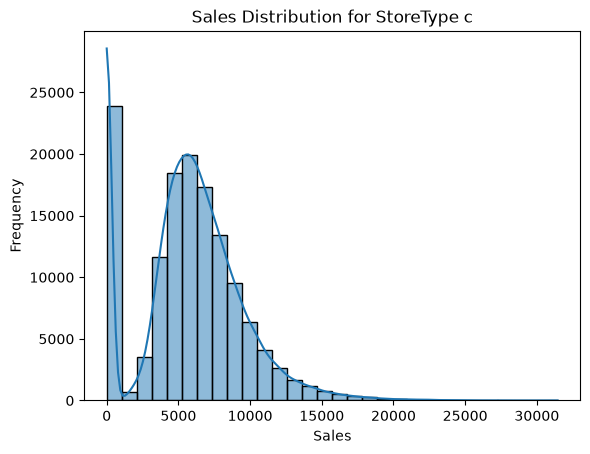

Description for StoreType a:


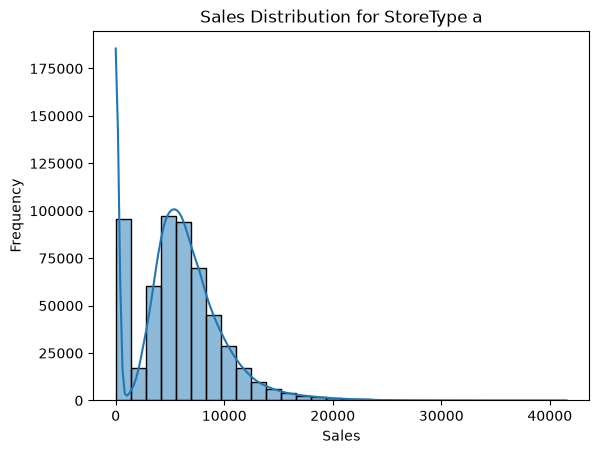

Description for StoreType d:


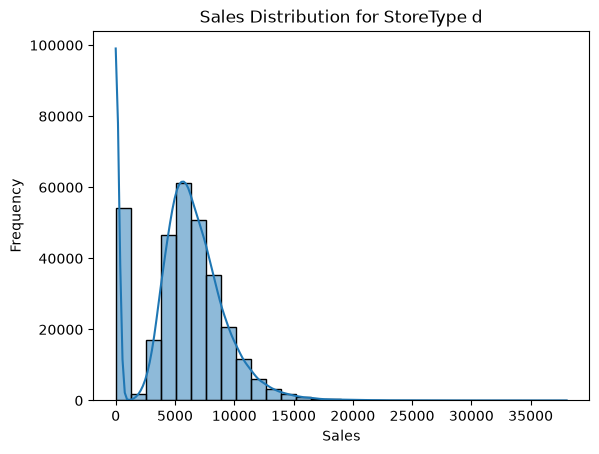

Description for StoreType b:


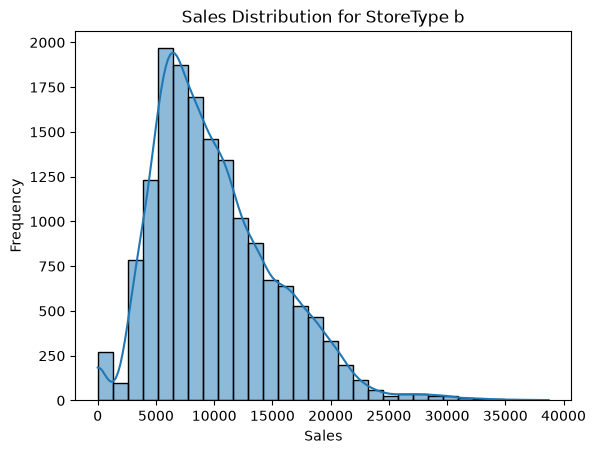

In [70]:
for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    sns.histplot(x=merged_df[merged_df['StoreType'] == i]['Sales'], bins=30, kde=True)
    plt.title(f'Sales Distribution for StoreType {i}')
    plt.xlabel('Sales')
    plt.ylabel('Frequency')
    plt.show()

Description for Assortment a:


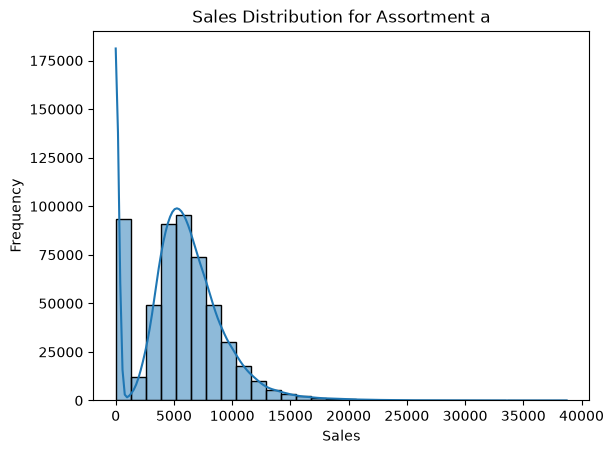

Description for Assortment c:


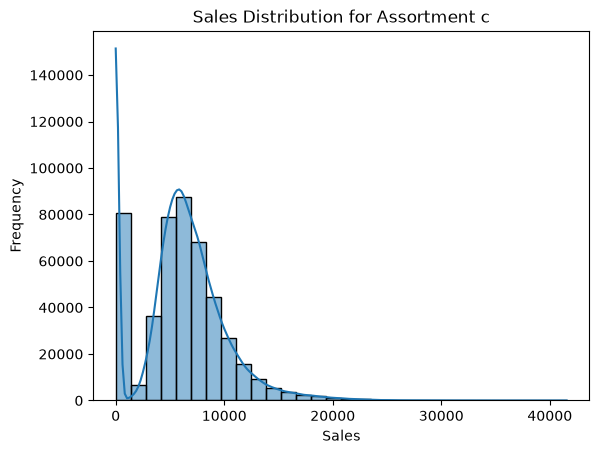

Description for Assortment b:


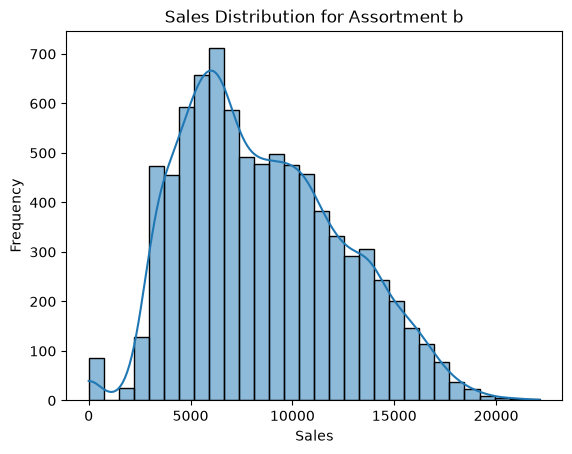

In [71]:
for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    sns.histplot(x=merged_df[merged_df['Assortment'] == i]['Sales'], bins=30, kde=True)
    plt.title(f'Sales Distribution for Assortment {i}')
    plt.xlabel('Sales')
    plt.ylabel('Frequency')
    plt.show()

Description for StoreType c:


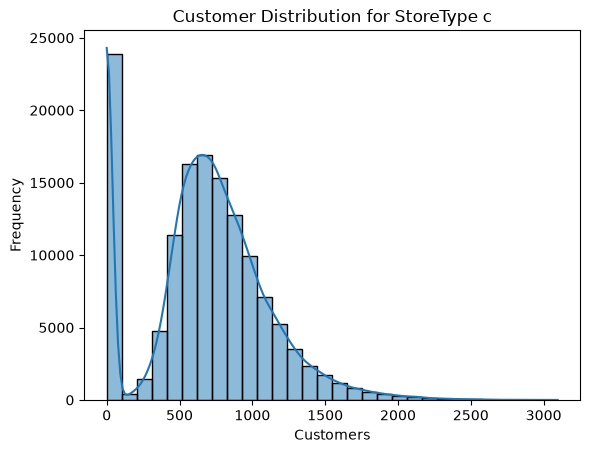

Description for StoreType a:


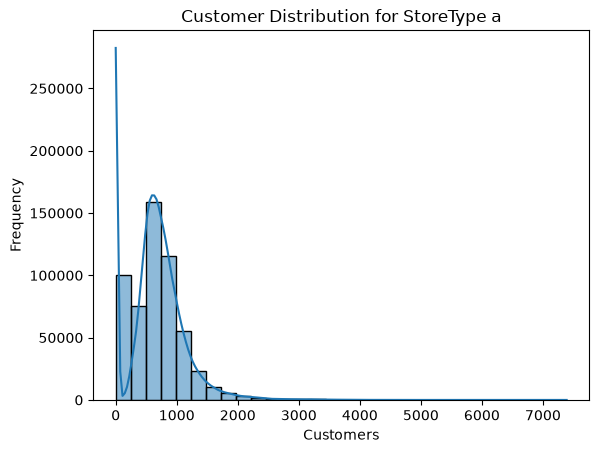

Description for StoreType d:


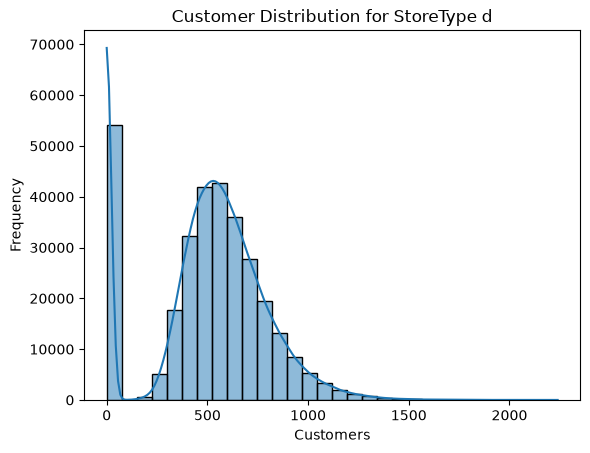

Description for StoreType b:


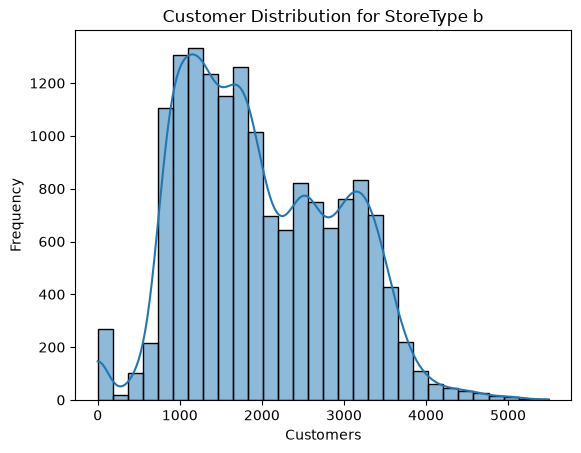

In [72]:
for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    sns.histplot(x=merged_df[merged_df['StoreType'] == i]['Customers'], bins=30, kde=True)
    plt.title(f'Customer Distribution for StoreType {i}')
    plt.xlabel('Customers')
    plt.ylabel('Frequency')
    plt.show()

Description for Assortment a:


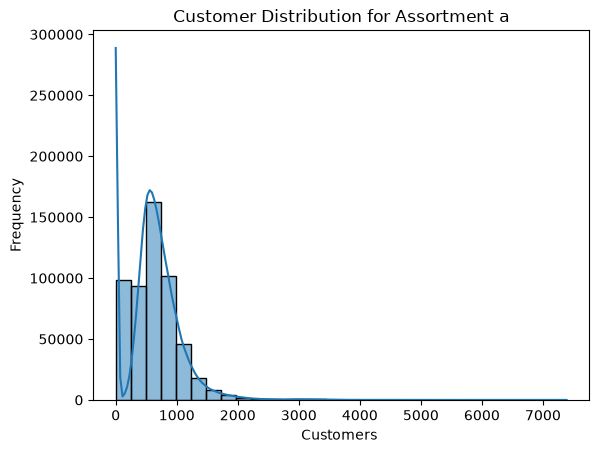

Description for Assortment c:


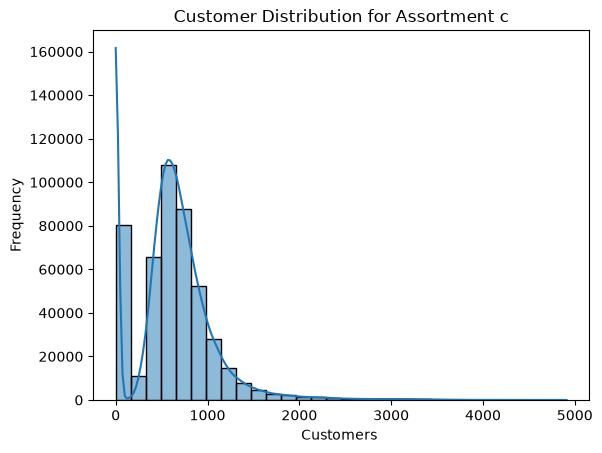

Description for Assortment b:


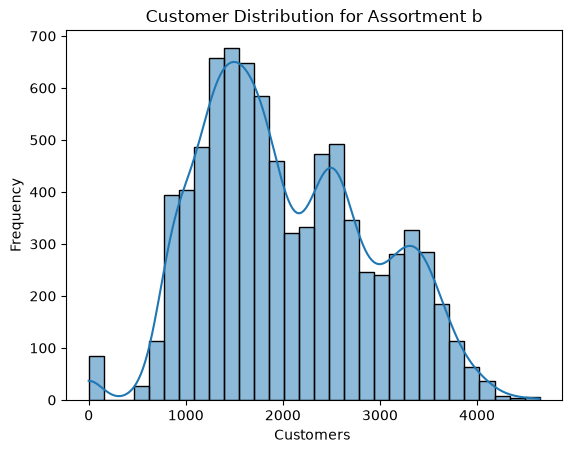

In [73]:
for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    sns.histplot(x=merged_df[merged_df['Assortment'] == i]['Customers'], bins=30, kde=True)
    plt.title(f'Customer Distribution for Assortment {i}')
    plt.xlabel('Customers ')
    plt.ylabel('Frequency')
    plt.show()

Description for Assortment a:


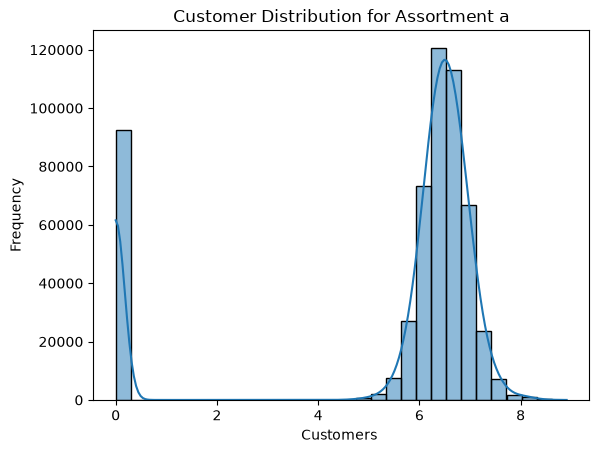

Description for Assortment c:


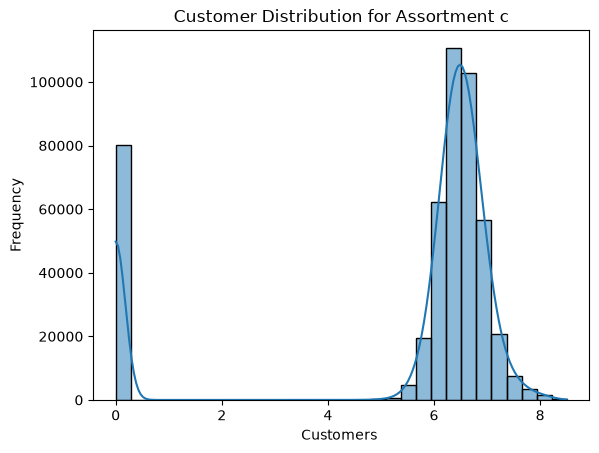

Description for Assortment b:


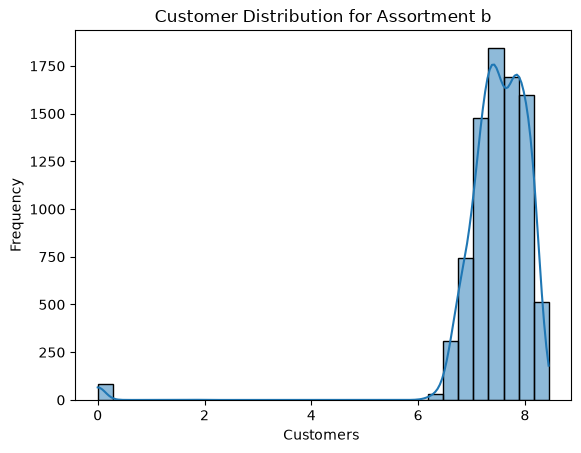

In [74]:
for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    sns.histplot(x=np.log(1 + merged_df[merged_df['Assortment'] == i]['Customers']), bins=30, kde=True)
    plt.title(f'Customer Distribution for Assortment {i}')
    plt.xlabel('Customers ')
    plt.ylabel('Frequency')
    plt.show()

In [75]:
for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    sns.histplot(x=merged_df[merged_df['Assortment'] == i & merged_df['Open'] == 1]['Customers'], bins=30, kde=True)
    plt.title(f'Customer Distribution for Assortment {i}')
    plt.xlabel('Customers ')
    plt.ylabel('Frequency')
    plt.show()

Description for Assortment a:


TypeError: Cannot perform 'rand_' with a dtyped [int64] array and scalar of type [bool]

Description for Assortment a:


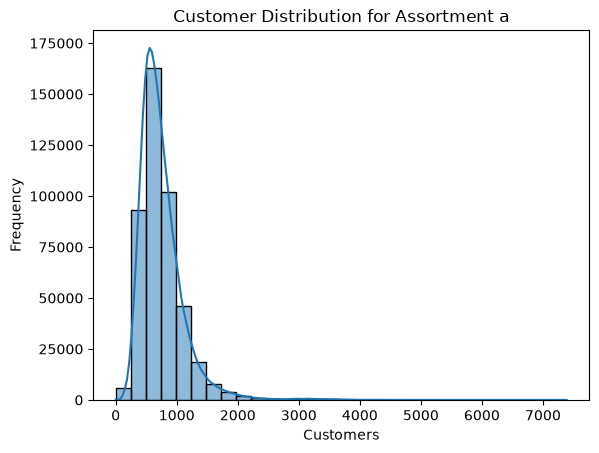

Description for Assortment c:


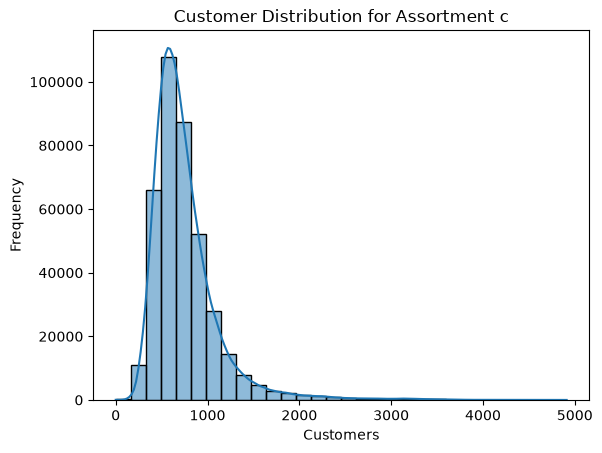

Description for Assortment b:


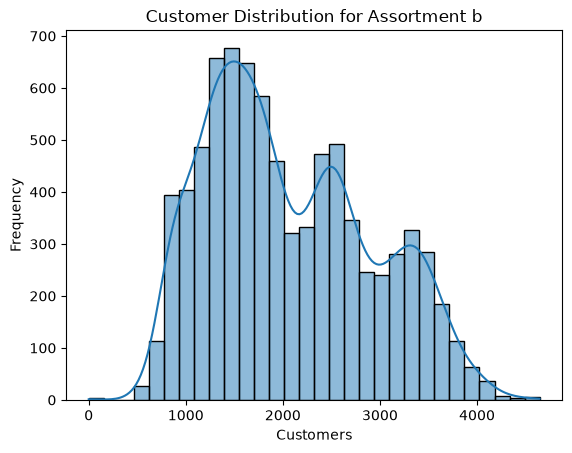

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    
    # Dono conditions ko brackets () mein rakhein
    subset = merged_df[(merged_df['Assortment'] == i) & (merged_df['Open'] == 1)]
    
    sns.histplot(x=subset['Customers'], bins=30, kde=True)
    plt.title(f'Customer Distribution for Assortment {i}')
    plt.xlabel('Customers')
    plt.ylabel('Frequency')
    plt.show()


Description for Assortment a:


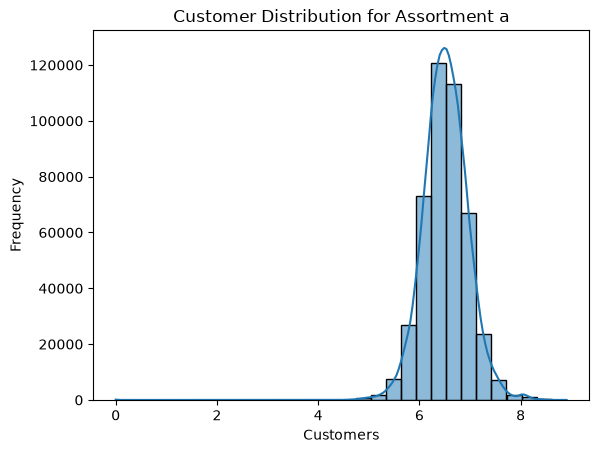

Description for Assortment c:


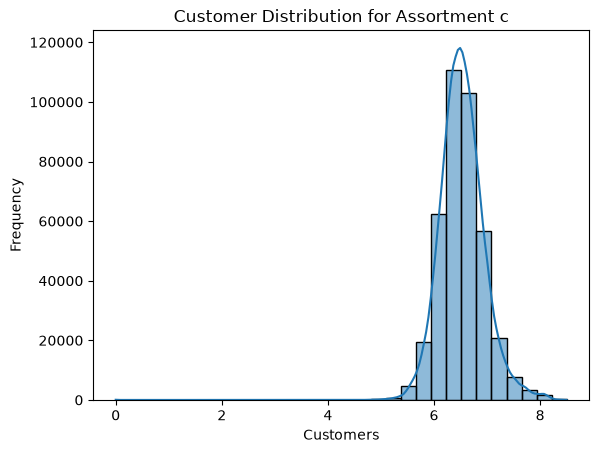

Description for Assortment b:


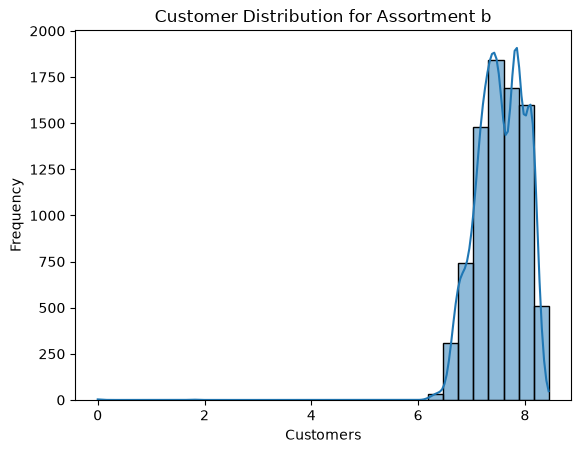

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

for i in merged_df['Assortment'].unique():
    print(f"Description for Assortment {i}:")
    
    # Dono conditions ko brackets () mein rakhein
    subset = merged_df[(merged_df['Assortment'] == i) & (merged_df['Open'] == 1)]
    
    sns.histplot(x=np.log(1 + subset['Customers']), bins=30, kde=True)
    plt.title(f'Customer Distribution for Assortment {i}')
    plt.xlabel('Customers')
    plt.ylabel('Frequency')
    plt.show()


Description for StoreType c:


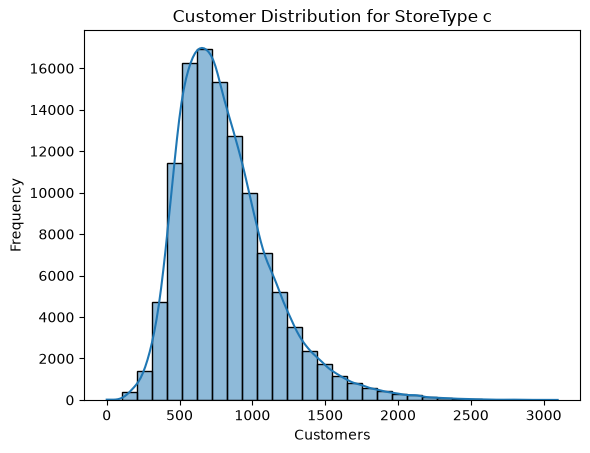

Description for StoreType a:


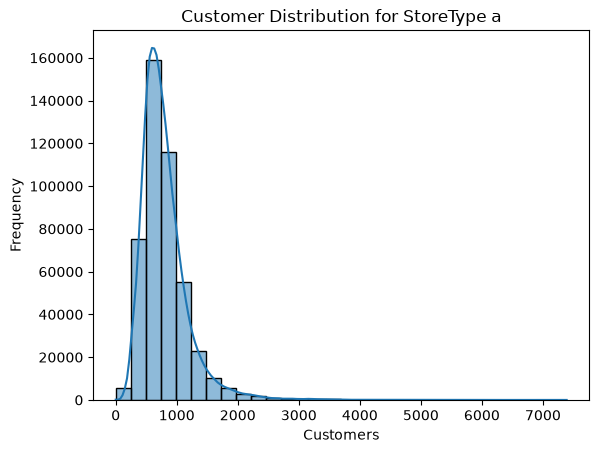

Description for StoreType d:


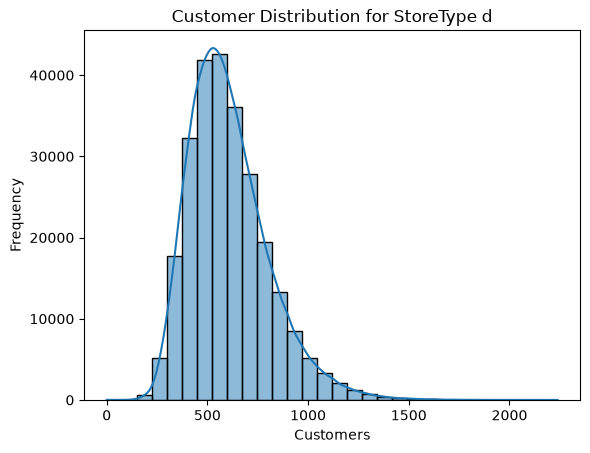

Description for StoreType b:


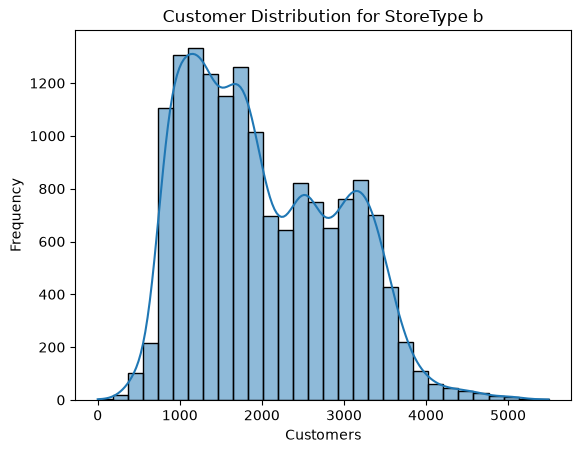

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    
    # Dono conditions ko brackets () mein rakhein
    subset = merged_df[(merged_df['StoreType'] == i) & (merged_df['Open'] == 1)]
    
    sns.histplot(x=subset['Customers'], bins=30, kde=True)
    plt.title(f'Customer Distribution for StoreType {i}')
    plt.xlabel('Customers')
    plt.ylabel('Frequency')
    plt.show()


Description for StoreType c:


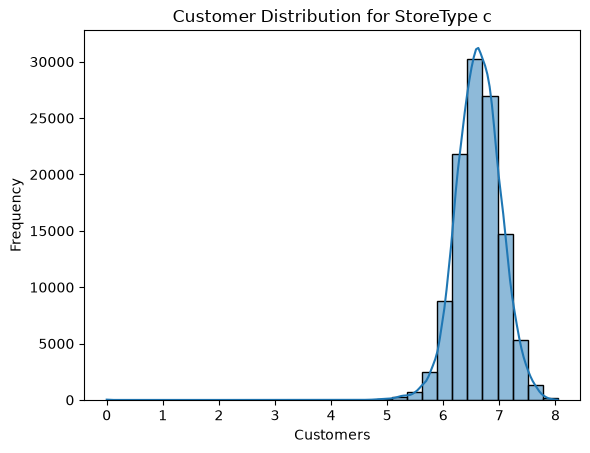

Description for StoreType a:


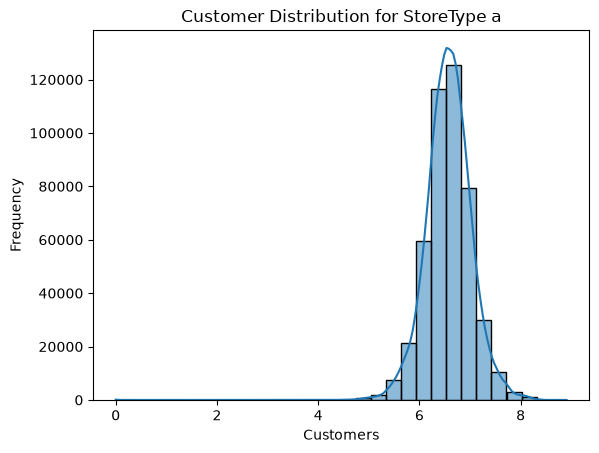

Description for StoreType d:


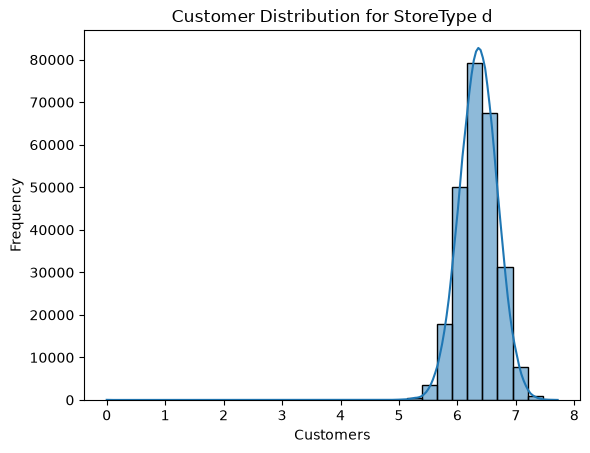

Description for StoreType b:


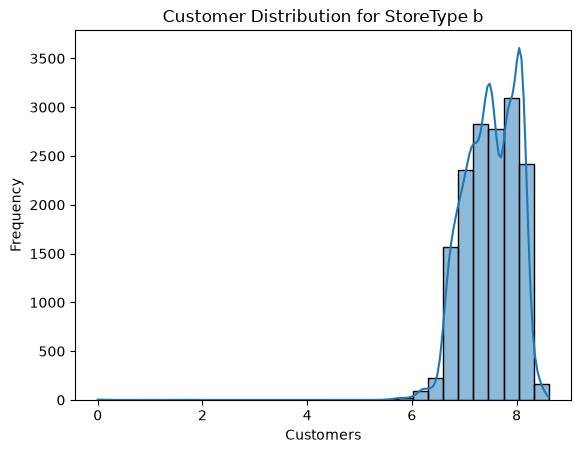

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

for i in merged_df['StoreType'].unique():
    print(f"Description for StoreType {i}:")
    
    # Dono conditions ko brackets () mein rakhein
    subset = merged_df[(merged_df['StoreType'] == i) & (merged_df['Open'] == 1)]
    
    sns.histplot(x=np.log(1 + subset['Customers']), bins=30, kde=True)
    plt.title(f'Customer Distribution for StoreType {i}')
    plt.xlabel('Customers')
    plt.ylabel('Frequency')
    plt.show()